In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os

# 设置中文显示
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 路径
clean_path = r'C:\Users\86151\Desktop\就业档案0921\电商用户经营分析\data\cleaned'
db_path = r'C:\Users\86151\Desktop\就业档案0921\电商用户经营分析\data\ecommerce.db'
screenshot_path = r'C:\Users\86151\Desktop\就业档案0921\电商用户经营分析\screenshots'

# 读宽表
wide = pd.read_csv(os.path.join(clean_path, 'wide_table.csv'))
daily_targets = pd.read_csv(os.path.join(clean_path, '..', 'raw', 'daily_targets.csv'))

print("宽表:", wide.shape)
print("目标表:", daily_targets.shape)

宽表: (7000, 25)
目标表: (365, 2)


In [51]:
# 月度净收入、订单量、客单价
monthly = wide.groupby('month').agg(
    订单量=('order_id', 'count'),
    净收入=('net_amount', 'sum'),
    去重订单量=('order_id', 'nunique')
).reset_index()

monthly['客单价'] = (monthly['净收入'] / monthly['去重订单量']).round(2)
monthly['净收入'] = monthly['净收入'].round(2)

print(monthly)

    month  订单量       净收入  去重订单量     客单价
0       1  587  75384.51    587  128.42
1       2  519  72633.36    519  139.95
2       3  631  82670.03    631  131.01
3       4  547  75547.50    547  138.11
4       5  602  86839.92    602  144.25
5       6  562  79185.87    562  140.90
6       7  608  79901.44    608  131.42
7       8  628  85068.34    628  135.46
8       9  562  73366.20    562  130.54
9      10  614  80098.07    614  130.45
10     11  556  71272.30    556  128.19
11     12  584  78233.85    584  133.96


In [52]:
# 目标表日期转格式
daily_targets['date'] = pd.to_datetime(daily_targets['date'])
daily_targets['month'] = daily_targets['date'].dt.month

# 月度目标
monthly_target = daily_targets.groupby('month')['target_revenue'].sum().reset_index()
monthly_target.columns = ['month', '目标收入']

# 合并
monthly = monthly.merge(monthly_target, on='month', how='left')
monthly['达成率'] = (monthly['净收入'] / monthly['目标收入'] * 100).round(2)

print(monthly)

    month  订单量       净收入  去重订单量     客单价    目标收入    达成率
0       1  587  75384.51    587  128.42  560017  13.46
1       2  519  72633.36    519  139.95  545937  13.30
2       3  631  82670.03    631  131.01  638790  12.94
3       4  547  75547.50    547  138.11  619383  12.20
4       5  602  86839.92    602  144.25  611217  14.21
5       6  562  79185.87    562  140.90  529741  14.95
6       7  608  79901.44    608  131.42  506871  15.76
7       8  628  85068.34    628  135.46  458571  18.55
8       9  562  73366.20    562  130.54  414065  17.72
9      10  614  80098.07    614  130.45  422617  18.95
10     11  556  71272.30    556  128.19  429237  16.60
11     12  584  78233.85    584  133.96  497148  15.74


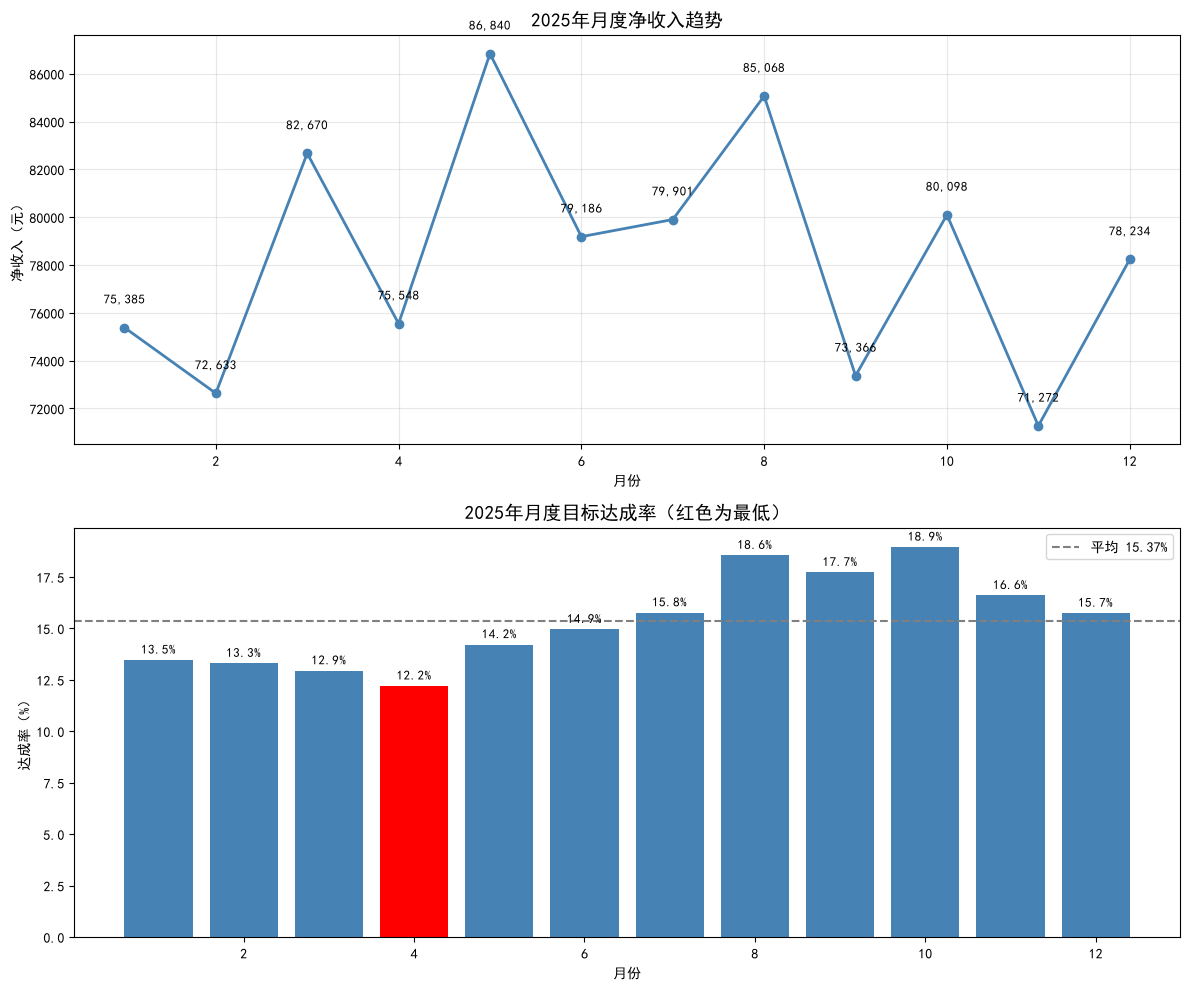

In [53]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# 图1：月度净收入趋势
axes[0].plot(monthly['month'], monthly['净收入'], marker='o', color='steelblue', linewidth=2)
axes[0].set_title('2025年月度净收入趋势', fontsize=14)
axes[0].set_xlabel('月份')
axes[0].set_ylabel('净收入（元）')
axes[0].grid(alpha=0.3)
for i, v in enumerate(monthly['净收入']):
    axes[0].text(monthly['month'][i], v + 1000, f'{v:,.0f}', ha='center', fontsize=9)

# 图2：月度目标达成率
colors = ['red' if x == monthly['达成率'].min() else 'steelblue' for x in monthly['达成率']]
axes[1].bar(monthly['month'], monthly['达成率'], color=colors)
axes[1].set_title('2025年月度目标达成率（红色为最低）', fontsize=14)
axes[1].set_xlabel('月份')
axes[1].set_ylabel('达成率（%）')
axes[1].axhline(y=monthly['达成率'].mean(), color='gray', linestyle='--', label=f'平均 {monthly["达成率"].mean():.2f}%')
axes[1].legend()
for i, v in enumerate(monthly['达成率']):
    axes[1].text(monthly['month'][i], v + 0.3, f'{v:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(screenshot_path, '月度趋势与达成率.png'), dpi=150, bbox_inches='tight')
plt.show()

In [54]:
# 最低和最高月份
min_month = monthly.loc[monthly['达成率'].idxmin()]
max_month = monthly.loc[monthly['达成率'].idxmax()]

print(f"达成率最低：{int(min_month['month'])}月，{min_month['达成率']}%")
print(f"达成率最高：{int(max_month['month'])}月，{max_month['达成率']}%")
print(f"全年平均达成率：{monthly['达成率'].mean():.2f}%")

# 净收入最高月份
top_revenue = monthly.loc[monthly['净收入'].idxmax()]
print(f"净收入最高：{int(top_revenue['month'])}月，{top_revenue['净收入']:,.2f}")

达成率最低：4月，12.2%
达成率最高：10月，18.95%
全年平均达成率：15.37%
净收入最高：5月，86,839.92


In [55]:
# 看4月的渠道、品类分布
apr = wide[wide['month'] == 4]

print("4月渠道分布:")
print(apr.groupby('channel')['net_amount'].sum().sort_values(ascending=False))

print("\n4月品类分布:")
print(apr.groupby('product_name')['net_amount'].sum().sort_values(ascending=False))

print("\n4月订单状态:")
print(apr['order_status'].value_counts())

4月渠道分布:
channel
APP    32430.11
小程序    19596.79
PC     12834.77
直播     10685.83
Name: net_amount, dtype: float64

4月品类分布:
product_name
精华     14446.80
面霜     13923.39
洗发水    13258.71
面膜     12906.56
防晒     12371.34
洁面      8640.70
Name: net_amount, dtype: float64

4月订单状态:
order_status
已完成    483
已退款     34
已取消     30
Name: count, dtype: int64


In [57]:
# 整体退款、取消
total = len(wide)
refund = wide['order_status'].value_counts()

print("订单状态分布:")
print(refund)
print(f"\n总订单: {total}")
print(f"退款率: {refund.get('已退款', 0) / total * 100:.2f}%")
print(f"取消率: {refund.get('已取消', 0) / total * 100:.2f}%")
print(f"完成率: {refund.get('已完成', 0) / total * 100:.2f}%")

订单状态分布:
order_status
已完成    6101
已退款     536
已取消     363
Name: count, dtype: int64

总订单: 7000
退款率: 7.66%
取消率: 5.19%
完成率: 87.16%


In [58]:
# 分月统计退款率
monthly_status = wide.groupby(['month', 'order_status']).size().unstack(fill_value=0)
monthly_status['总订单'] = monthly_status.sum(axis=1)
monthly_status['退款率'] = (monthly_status.get('已退款', 0) / monthly_status['总订单'] * 100).round(2)
monthly_status['取消率'] = (monthly_status.get('已取消', 0) / monthly_status['总订单'] * 100).round(2)

print(monthly_status)

order_status  已取消  已完成  已退款  总订单   退款率   取消率
month                                       
1              35  510   42  587  7.16  5.96
2              21  452   46  519  8.86  4.05
3              38  550   43  631  6.81  6.02
4              30  483   34  547  6.22  5.48
5              30  533   39  602  6.48  4.98
6              30  491   41  562  7.30  5.34
7              16  543   49  608  8.06  2.63
8              35  543   50  628  7.96  5.57
9              30  476   56  562  9.96  5.34
10             29  542   43  614  7.00  4.72
11             34  476   46  556  8.27  6.12
12             35  502   47  584  8.05  5.99


In [59]:
# 各品类退款率
cat_status = wide.groupby(['product_name', 'order_status']).size().unstack(fill_value=0)
cat_status['总订单'] = cat_status.sum(axis=1)
cat_status['退款率'] = (cat_status.get('已退款', 0) / cat_status['总订单'] * 100).round(2)
cat_status = cat_status.sort_values('退款率', ascending=False)

print(cat_status[['总订单', '已退款', '退款率']])

order_status   总订单  已退款   退款率
product_name                 
洁面            1128  100  8.87
防晒            1213   93  7.67
洗发水           1165   87  7.47
面霜            1208   90  7.45
精华            1123   82  7.30
面膜            1163   84  7.22


In [60]:
# 各渠道退款率
ch_status = wide.groupby(['channel', 'order_status']).size().unstack(fill_value=0)
ch_status['总订单'] = ch_status.sum(axis=1)
ch_status['退款率'] = (ch_status.get('已退款', 0) / ch_status['总订单'] * 100).round(2)
ch_status = ch_status.sort_values('退款率', ascending=False)

print(ch_status[['总订单', '已退款', '退款率']])

order_status   总订单  已退款   退款率
channel                      
小程序           1939  170  8.77
APP           2896  218  7.53
PC            1309   93  7.10
直播             856   55  6.43


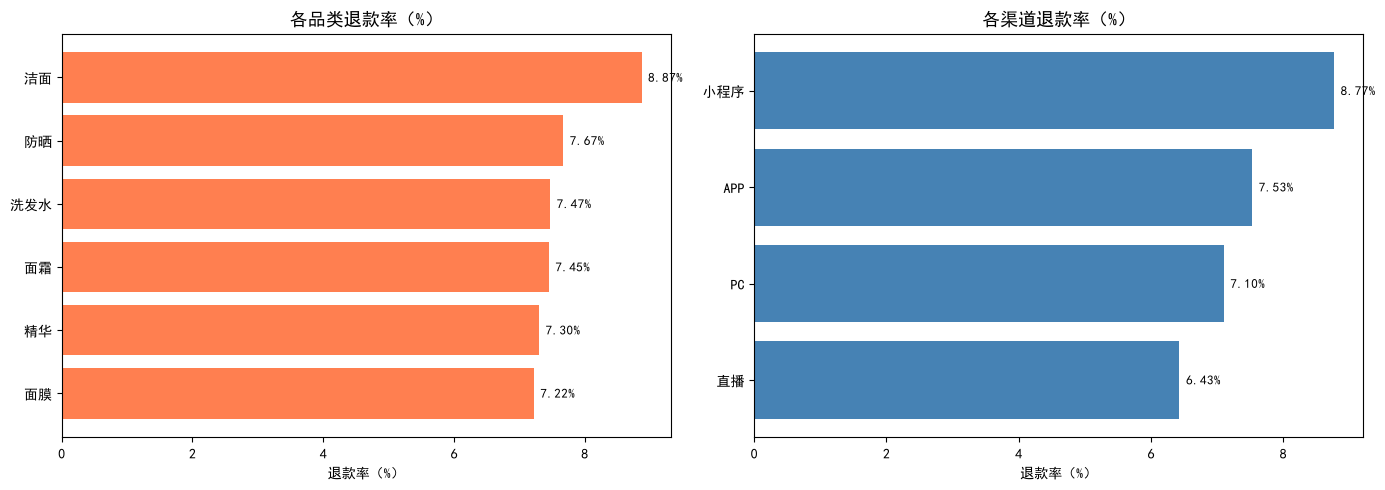

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 图1：各品类退款率
cat_plot = cat_status.sort_values('退款率')
axes[0].barh(cat_plot.index, cat_plot['退款率'], color='coral')
axes[0].set_title('各品类退款率（%）', fontsize=13)
axes[0].set_xlabel('退款率（%）')
for i, v in enumerate(cat_plot['退款率']):
    axes[0].text(v + 0.1, i, f'{v:.2f}%', va='center', fontsize=9)

# 图2：各渠道退款率
ch_plot = ch_status.sort_values('退款率')
axes[1].barh(ch_plot.index, ch_plot['退款率'], color='steelblue')
axes[1].set_title('各渠道退款率（%）', fontsize=13)
axes[1].set_xlabel('退款率（%）')
for i, v in enumerate(ch_plot['退款率']):
    axes[1].text(v + 0.1, i, f'{v:.2f}%', va='center', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(screenshot_path, '退款率分析.png'), dpi=150, bbox_inches='tight')
plt.show()

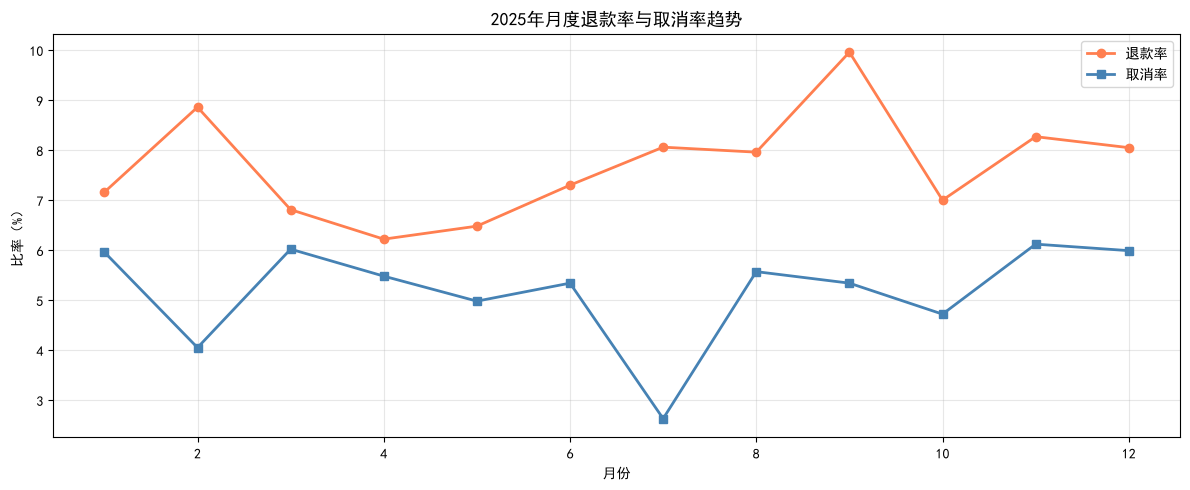

In [62]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_status.index, monthly_status['退款率'], marker='o', color='coral', linewidth=2, label='退款率')
ax.plot(monthly_status.index, monthly_status['取消率'], marker='s', color='steelblue', linewidth=2, label='取消率')
ax.set_title('2025年月度退款率与取消率趋势', fontsize=13)
ax.set_xlabel('月份')
ax.set_ylabel('比率（%）')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(screenshot_path, '月度退款率趋势.png'), dpi=150, bbox_inches='tight')
plt.show()

In [63]:
print("=== 退款分析结论 ===")
print(f"整体退款率: {refund.get('已退款', 0) / total * 100:.2f}%")
print(f"退款率最高的品类: {cat_status.index[0]}，{cat_status['退款率'].iloc[0]:.2f}%")
print(f"退款率最低的品类: {cat_status.index[-1]}，{cat_status['退款率'].iloc[-1]:.2f}%")
print(f"退款率最高的渠道: {ch_status.index[0]}，{ch_status['退款率'].iloc[0]:.2f}%")
print(f"退款率最低的渠道: {ch_status.index[-1]}，{ch_status['退款率'].iloc[-1]:.2f}%")
print(f"退款率最高的月份: {monthly_status['退款率'].idxmax()}月，{monthly_status['退款率'].max():.2f}%")

=== 退款分析结论 ===
整体退款率: 7.66%
退款率最高的品类: 洁面，8.87%
退款率最低的品类: 面膜，7.22%
退款率最高的渠道: 小程序，8.77%
退款率最低的渠道: 直播，6.43%
退款率最高的月份: 9月，9.96%


In [64]:
# 品类分析/品类净收入与客单价
cat = wide.groupby('product_name').agg(
    订单量=('order_id', 'count'),
    净收入=('net_amount', 'sum'),
    去重订单量=('order_id', 'nunique')
).reset_index()
cat['客单价'] = (cat['净收入'] / cat['去重订单量']).round(2)
cat['净收入'] = cat['净收入'].round(2)
cat = cat.sort_values('净收入', ascending=False)

print(cat)

  product_name   订单量        净收入  去重订单量     客单价
4           面膜  1163  180274.16   1163  155.01
5           面霜  1208  173116.55   1208  143.31
1          洗发水  1165  170217.78   1165  146.11
2           精华  1123  161193.40   1123  143.54
3           防晒  1213  159247.50   1213  131.28
0           洁面  1128   96152.00   1128   85.24


In [65]:
# 渠道分析/渠道净收入与客单价
ch = wide.groupby('channel').agg(
    订单量=('order_id', 'count'),
    净收入=('net_amount', 'sum'),
    去重订单量=('order_id', 'nunique')
).reset_index()
ch['客单价'] = (ch['净收入'] / ch['去重订单量']).round(2)
ch['净收入'] = ch['净收入'].round(2)
ch = ch.sort_values('净收入', ascending=False)

print(ch)

  channel   订单量        净收入  去重订单量     客单价
0     APP  2896  389693.35   2896  134.56
2     小程序  1939  254827.12   1939  131.42
1      PC  1309  177136.82   1309  135.32
3      直播   856  118544.10    856  138.49


In [66]:
# 渠道 × 品类 净收入 /交叉分析（渠道 × 品类）
cross = wide.pivot_table(
    index='channel',
    columns='product_name',
    values='net_amount',
    aggfunc='sum'
).round(2)

print(cross)

product_name        洁面       洗发水        精华        防晒        面膜        面霜
channel                                                                 
APP           35876.81  66738.41  73371.23  64568.51  76124.93  73013.46
PC            18684.72  34467.65  25902.68  32530.83  31576.44  33974.50
小程序           28006.67  49714.06  42080.84  39877.06  50235.88  44912.61
直播            13583.80  19297.66  19838.65  22271.10  22336.91  21215.98


In [68]:
# 支付方式
pay = wide.groupby('payment_method').agg(
    订单量=('order_id', 'count'),
    净收入=('net_amount', 'sum')
).reset_index()
pay['净收入'] = pay['净收入'].round(2)
pay['占比'] = (pay['净收入'] / pay['净收入'].sum() * 100).round(2)
pay = pay.sort_values('净收入', ascending=False)

print(pay)

  payment_method   订单量        净收入     占比
0             微信  3709  510727.04  54.32
1            支付宝  2606  348288.36  37.04
2            银行卡   685   81185.99   8.63


In [70]:
print(wide['payment_method'].unique())
print(wide['payment_method'].value_counts())

<StringArray>
['支付宝', '微信', '银行卡']
Length: 3, dtype: str
payment_method
微信     3709
支付宝    2606
银行卡     685
Name: count, dtype: int64


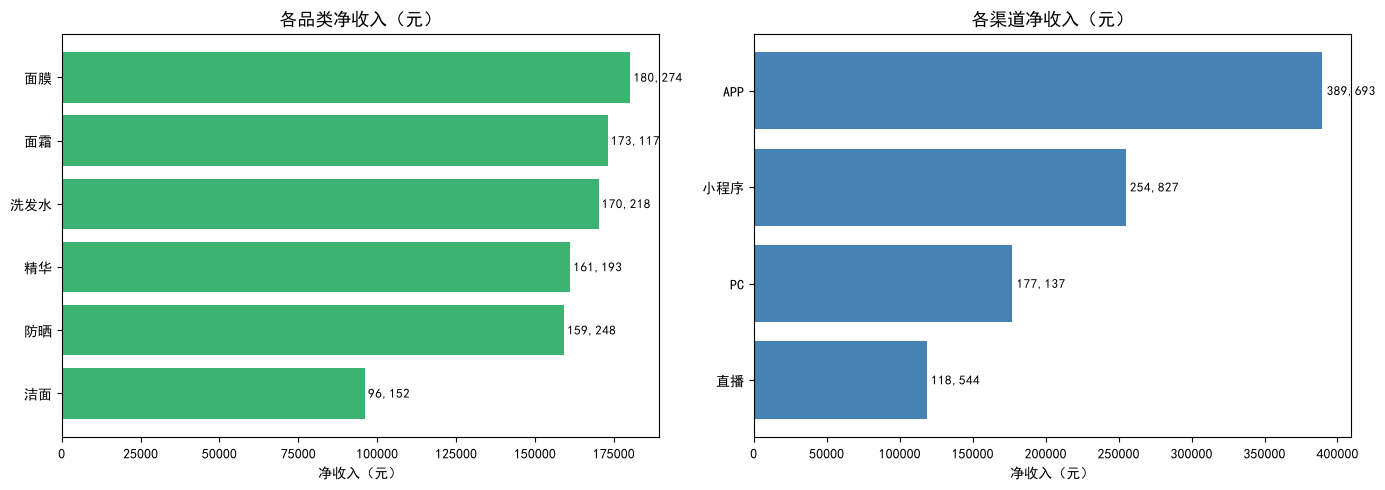

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 图1：品类净收入
cat_plot = cat.sort_values('净收入')
axes[0].barh(cat_plot['product_name'], cat_plot['净收入'], color='mediumseagreen')
axes[0].set_title('各品类净收入（元）', fontsize=13)
axes[0].set_xlabel('净收入（元）')
for i, v in enumerate(cat_plot['净收入']):
    axes[0].text(v + 1000, i, f'{v:,.0f}', va='center', fontsize=9)

# 图2：渠道净收入
ch_plot = ch.sort_values('净收入')
axes[1].barh(ch_plot['channel'], ch_plot['净收入'], color='steelblue')
axes[1].set_title('各渠道净收入（元）', fontsize=13)
axes[1].set_xlabel('净收入（元）')
for i, v in enumerate(ch_plot['净收入']):
    axes[1].text(v + 3000, i, f'{v:,.0f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(screenshot_path, '品类与渠道分析.png'), dpi=150, bbox_inches='tight')
plt.show()

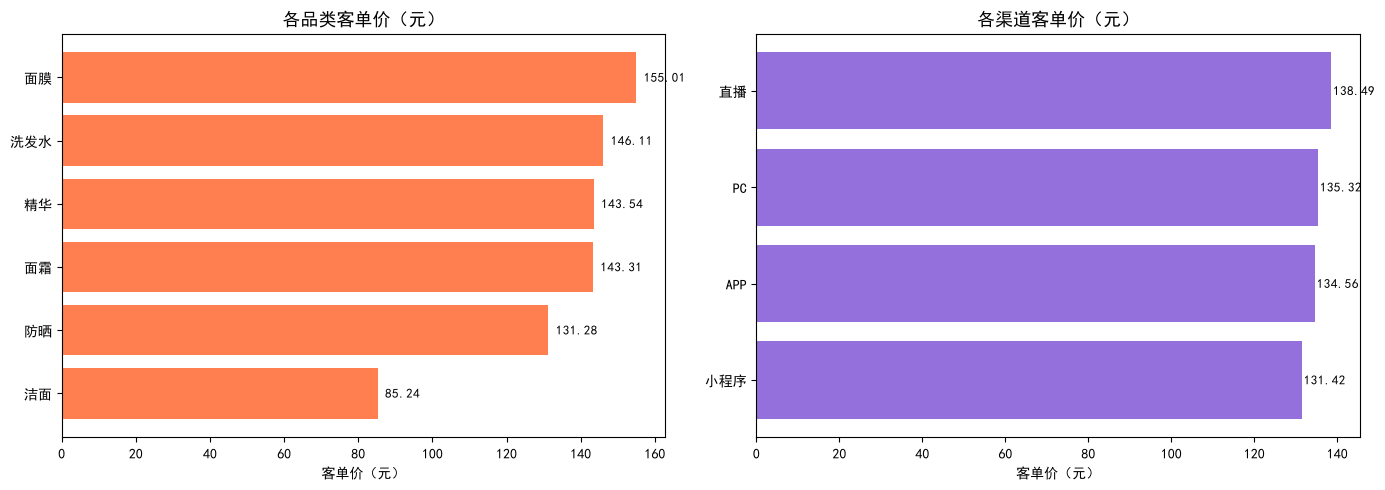

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 品类客单价
cat_sorted = cat.sort_values('客单价')
axes[0].barh(cat_sorted['product_name'], cat_sorted['客单价'], color='coral')
axes[0].set_title('各品类客单价（元）', fontsize=13)
axes[0].set_xlabel('客单价（元）')
for i, v in enumerate(cat_sorted['客单价']):
    axes[0].text(v + 2, i, f'{v:.2f}', va='center', fontsize=9)

# 渠道客单价
ch_sorted = ch.sort_values('客单价')
axes[1].barh(ch_sorted['channel'], ch_sorted['客单价'], color='mediumpurple')
axes[1].set_title('各渠道客单价（元）', fontsize=13)
axes[1].set_xlabel('客单价（元）')
for i, v in enumerate(ch_sorted['客单价']):
    axes[1].text(v + 0.5, i, f'{v:.2f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(screenshot_path, '客单价对比.png'), dpi=150, bbox_inches='tight')
plt.show()

In [74]:
print("=== 品类与渠道分析结论 ===")
print(f"净收入最高品类: {cat.iloc[0]['product_name']}，{cat.iloc[0]['净收入']:,.2f}")
print(f"净收入最低品类: {cat.iloc[-1]['product_name']}，{cat.iloc[-1]['净收入']:,.2f}")
print(f"客单价最高品类: {cat.sort_values('客单价').iloc[-1]['product_name']}，{cat.sort_values('客单价').iloc[-1]['客单价']}")
print(f"客单价最低品类: {cat.sort_values('客单价').iloc[0]['product_name']}，{cat.sort_values('客单价').iloc[0]['客单价']}")
print()
print(f"净收入最高渠道: {ch.iloc[0]['channel']}，{ch.iloc[0]['净收入']:,.2f}")
print(f"客单价最高渠道: {ch.sort_values('客单价').iloc[-1]['channel']}，{ch.sort_values('客单价').iloc[-1]['客单价']}")
print()
print(f"支付方式净收入最高: {pay.iloc[0]['payment_method']}，{pay.iloc[0]['净收入']:,.2f}，占比{pay.iloc[0]['占比']}%")

=== 品类与渠道分析结论 ===
净收入最高品类: 面膜，180,274.16
净收入最低品类: 洁面，96,152.00
客单价最高品类: 面膜，155.01
客单价最低品类: 洁面，85.24

净收入最高渠道: APP，389,693.35
客单价最高渠道: 直播，138.49

支付方式净收入最高: 微信，510,727.04，占比54.32%


In [78]:
# 算每个用户的 R、F、M
# 以 2025-12-31 为基准日
snapshot_date = pd.Timestamp('2025-12-31')

# 只算有效订单（已完成）
valid = wide[wide['order_status'] == '已完成'].copy()

# 按用户聚合
rfm = valid.groupby('user_id').agg(
    最近购买日=('order_date', 'max'),
    购买次数=('order_id', 'nunique'),
    消费金额=('net_amount', 'sum')
).reset_index()

# R = 距基准日天数
rfm['最近购买日'] = pd.to_datetime(rfm['最近购买日'])
rfm['R'] = (snapshot_date - rfm['最近购买日']).dt.days
rfm['F'] = rfm['购买次数']
rfm['M'] = rfm['消费金额'].round(2)

print("RFM形状:", rfm.shape)
print(rfm.head())
print(rfm[['R', 'F', 'M']].describe())

RFM形状: (1196, 7)
   user_id      最近购买日  购买次数    消费金额    R  F       M
0    10001 2025-12-22     7  544.95    9  7  544.95
1    10002 2025-03-15     2  211.59  291  2  211.59
2    10003 2025-11-23     5  487.40   38  5  487.40
3    10004 2025-05-06     2  220.51  239  2  220.51
4    10005 2025-11-16     3  672.31   45  3  672.31
                 R            F            M
count  1196.000000  1196.000000  1196.000000
mean     69.158027     5.101171   786.121564
std      66.812603     2.248339   472.662577
min       0.000000     1.000000    29.340000
25%      20.000000     3.000000   419.172500
50%      47.500000     5.000000   696.580000
75%      96.000000     7.000000  1052.162500
max     358.000000    14.000000  3167.340000


In [79]:
#打分、打标签。
# R：天数越小越好，所以反向打分
rfm['R_score'] = pd.qcut(rfm['R'], 5, labels=[5, 4, 3, 2, 1]).astype(int)

# F：次数越多越好
rfm['F_score'] = pd.qcut(rfm['F'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# M：金额越多越好
rfm['M_score'] = pd.qcut(rfm['M'], 5, labels=[1, 2, 3, 4, 5]).astype(int)

print(rfm[['user_id', 'R', 'F', 'M', 'R_score', 'F_score', 'M_score']].head(10))

#注意：F 可能有很多重复值，用 rank(method='first') 避免 qcut 报错。

   user_id    R  F        M  R_score  F_score  M_score
0    10001    9  7   544.95        5        4        2
1    10002  291  2   211.59        1        1        1
2    10003   38  5   487.40        3        3        2
3    10004  239  2   220.51        1        1        1
4    10005   45  3   672.31        3        1        3
5    10006  187  4   359.76        1        2        1
6    10007    6  4   622.21        5        2        3
7    10008   56  6   936.93        3        3        4
8    10009   70  7  1194.90        2        4        5
9    10010  170  4   501.47        1        2        2


In [80]:
# 拼接 RFM 得分
rfm['RFM'] = rfm['R_score'].astype(str) + rfm['F_score'].astype(str) + rfm['M_score'].astype(str)

# 定义用户分层规则
def segment(row):
    r, f, m = row['R_score'], row['F_score'], row['M_score']
    if r >= 4 and f >= 4 and m >= 4:
        return '重要价值用户'
    elif r >= 4 and f >= 4 and m < 4:
        return '重要保持用户'
    elif r >= 4 and f < 4 and m >= 4:
        return '重要发展用户'
    elif r >= 4 and f < 4 and m < 4:
        return '重要挽留用户'
    elif r < 4 and f >= 4 and m >= 4:
        return '一般价值用户'
    elif r < 4 and f >= 4 and m < 4:
        return '一般保持用户'
    elif r < 4 and f < 4 and m >= 4:
        return '一般发展用户'
    else:
        return '一般挽留用户'

rfm['用户分层'] = rfm.apply(segment, axis=1)

print(rfm['用户分层'].value_counts())

用户分层
一般挽留用户    412
重要价值用户    197
重要挽留用户    189
一般价值用户    164
一般发展用户     72
重要保持用户     60
一般保持用户     57
重要发展用户     45
Name: count, dtype: int64


In [81]:
# 各层人数、占比、消费贡献
seg = rfm.groupby('用户分层').agg(
    人数=('user_id', 'count'),
    消费总额=('M', 'sum'),
    平均消费=('M', 'mean')
).reset_index()

seg['人数占比'] = (seg['人数'] / seg['人数'].sum() * 100).round(2)
seg['消费占比'] = (seg['消费总额'] / seg['消费总额'].sum() * 100).round(2)
seg['平均消费'] = seg['平均消费'].round(2)
seg = seg.sort_values('消费总额', ascending=False)

print(seg)

     用户分层   人数       消费总额     平均消费   人数占比   消费占比
4  重要价值用户  197  266114.07  1350.83  16.47  28.30
0  一般价值用户  164  208160.76  1269.27  13.71  22.14
3  一般挽留用户  412  176572.87   428.57  34.45  18.78
7  重要挽留用户  189   86786.21   459.19  15.80   9.23
2  一般发展用户   72   74257.17  1031.35   6.02   7.90
6  重要发展用户   45   50269.84  1117.11   3.76   5.35
5  重要保持用户   60   40996.92   683.28   5.02   4.36
1  一般保持用户   57   37043.55   649.89   4.77   3.94


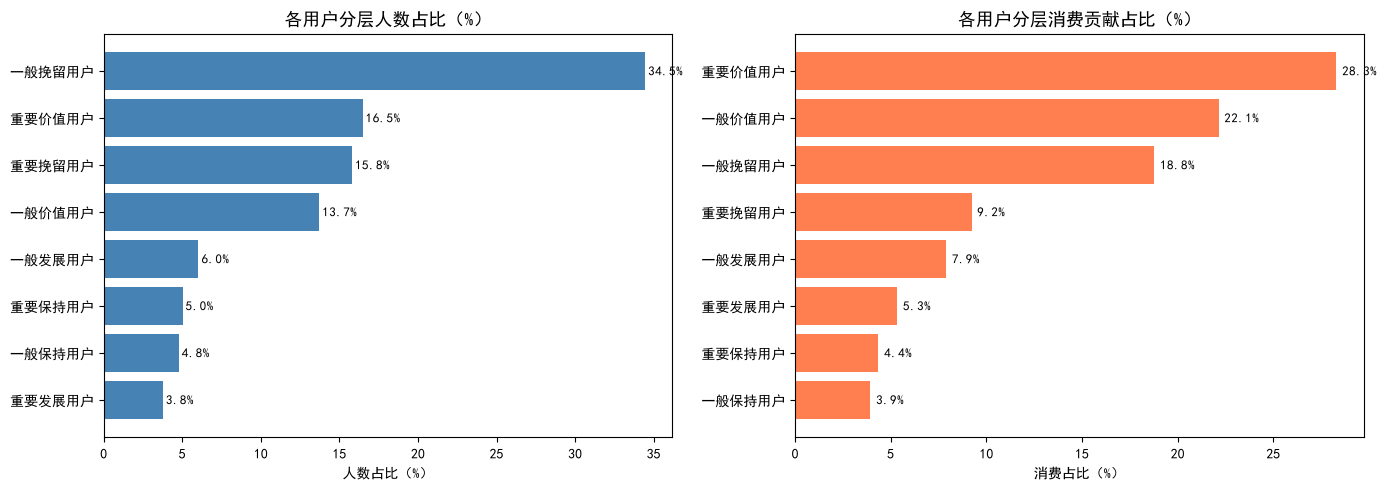

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 图1：各层人数占比
seg_sorted = seg.sort_values('人数占比')
axes[0].barh(seg_sorted['用户分层'], seg_sorted['人数占比'], color='steelblue')
axes[0].set_title('各用户分层人数占比（%）', fontsize=13)
axes[0].set_xlabel('人数占比（%）')
for i, v in enumerate(seg_sorted['人数占比']):
    axes[0].text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=9)

# 图2：各层消费占比
seg_sorted2 = seg.sort_values('消费占比')
axes[1].barh(seg_sorted2['用户分层'], seg_sorted2['消费占比'], color='coral')
axes[1].set_title('各用户分层消费贡献占比（%）', fontsize=13)
axes[1].set_xlabel('消费占比（%）')
for i, v in enumerate(seg_sorted2['消费占比']):
    axes[1].text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(screenshot_path, 'RFM用户分层.png'), dpi=150, bbox_inches='tight')
plt.show()

In [83]:
#输出结论
print("=== RFM分析结论 ===")
print(f"总用户数: {len(rfm)}")
print()
print("各层人数占比:")
for _, row in seg.iterrows():
    print(f"  {row['用户分层']}: {row['人数']}人 ({row['人数占比']}%)，消费贡献 {row['消费占比']}%")

# 高价值用户（重要价值 + 重要保持 + 重要发展）
high_value = rfm[rfm['用户分层'].isin(['重要价值用户', '重要保持用户', '重要发展用户'])]
print()
print(f"高价值用户数: {len(high_value)}，占比 {len(high_value)/len(rfm)*100:.2f}%")
print(f"高价值用户消费贡献: {high_value['M'].sum()/rfm['M'].sum()*100:.2f}%")

=== RFM分析结论 ===
总用户数: 1196

各层人数占比:
  重要价值用户: 197人 (16.47%)，消费贡献 28.3%
  一般价值用户: 164人 (13.71%)，消费贡献 22.14%
  一般挽留用户: 412人 (34.45%)，消费贡献 18.78%
  重要挽留用户: 189人 (15.8%)，消费贡献 9.23%
  一般发展用户: 72人 (6.02%)，消费贡献 7.9%
  重要发展用户: 45人 (3.76%)，消费贡献 5.35%
  重要保持用户: 60人 (5.02%)，消费贡献 4.36%
  一般保持用户: 57人 (4.77%)，消费贡献 3.94%

高价值用户数: 302，占比 25.25%
高价值用户消费贡献: 38.01%


In [84]:
# 第8步：用户画像与复购分析
# 性别与年龄分布
# 用 users 表
users_clean = pd.read_csv(os.path.join(clean_path, 'users_clean.csv'))

# 性别分布
gender = users_clean['gender'].value_counts()
print("性别分布:")
print(gender)
print(f"女性占比: {gender.get('女', 0) / gender.sum() * 100:.2f}%")
print(f"男性占比: {gender.get('男', 0) / gender.sum() * 100:.2f}%")

# 年龄段
bins = [0, 25, 30, 35, 40, 100]
labels = ['25岁以下', '25-30', '30-35', '35-40', '40岁以上']
users_clean['年龄段'] = pd.cut(users_clean['age'], bins=bins, labels=labels, right=False)

age_dist = users_clean['年龄段'].value_counts().sort_index()
print("\n年龄段分布:")
print(age_dist)

性别分布:
gender
女    641
男    559
Name: count, dtype: int64
女性占比: 53.42%
男性占比: 46.58%

年龄段分布:
年龄段
25岁以下    317
25-30    309
30-35    309
35-40    175
40岁以上     90
Name: count, dtype: int64


In [85]:
# 地域分布
# 大区分布
region = users_clean['region'].value_counts()
print("大区分布:")
print(region)

# 城市Top10
city_top = users_clean['city'].value_counts().head(10)
print("\n城市Top10:")
print(city_top)

大区分布:
region
华东    290
华南    224
西南    178
华北    159
华中    135
东北    111
西北    103
Name: count, dtype: int64

城市Top10:
city
杭州    85
苏州    72
上海    70
深圳    64
南京    64
广州    58
福州    51
厦门    50
成都    49
贵阳    49
Name: count, dtype: int64


In [86]:
# 复购率
# 每个用户的购买次数
user_orders = wide[wide['order_status'] == '已完成'].groupby('user_id')['order_id'].nunique()

# 复购用户 = 购买次数 >= 2
repeat_users = (user_orders >= 2).sum()
total_users = len(user_orders)
repeat_rate = repeat_users / total_users * 100

print(f"总购买用户: {total_users}")
print(f"复购用户（≥2次）: {repeat_users}")
print(f"复购率: {repeat_rate:.2f}%")

# 购买次数分布
print("\n购买次数分布:")
print(user_orders.value_counts().sort_index())

总购买用户: 1196
复购用户（≥2次）: 1157
复购率: 96.74%

购买次数分布:
order_id
1      39
2      92
3     173
4     231
5     182
6     162
7     145
8      82
9      53
10     15
11     15
12      2
13      4
14      1
Name: count, dtype: int64


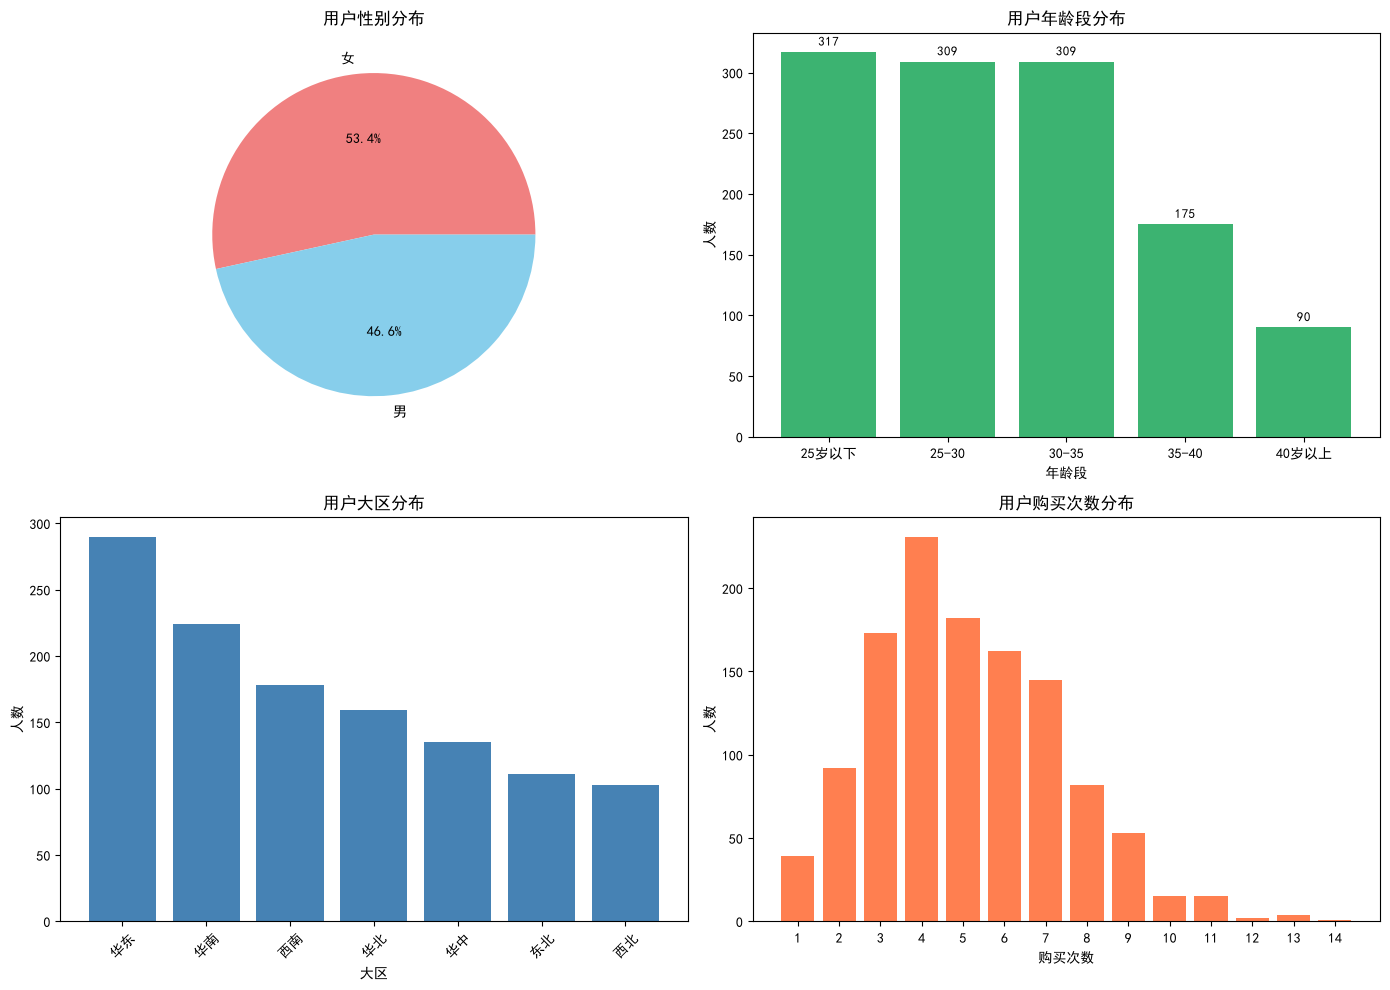

In [87]:
# 画图
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 图1：性别
axes[0, 0].pie(gender.values, labels=gender.index, autopct='%1.1f%%', colors=['lightcoral', 'skyblue'])
axes[0, 0].set_title('用户性别分布')

# 图2：年龄段
axes[0, 1].bar(age_dist.index.astype(str), age_dist.values, color='mediumseagreen')
axes[0, 1].set_title('用户年龄段分布')
axes[0, 1].set_xlabel('年龄段')
axes[0, 1].set_ylabel('人数')
for i, v in enumerate(age_dist.values):
    axes[0, 1].text(i, v + 5, str(v), ha='center', fontsize=9)

# 图3：大区分布
axes[1, 0].bar(region.index, region.values, color='steelblue')
axes[1, 0].set_title('用户大区分布')
axes[1, 0].set_xlabel('大区')
axes[1, 0].set_ylabel('人数')
axes[1, 0].tick_params(axis='x', rotation=45)

# 图4：购买次数分布
order_dist = user_orders.value_counts().sort_index()
axes[1, 1].bar(order_dist.index.astype(str), order_dist.values, color='coral')
axes[1, 1].set_title('用户购买次数分布')
axes[1, 1].set_xlabel('购买次数')
axes[1, 1].set_ylabel('人数')

plt.tight_layout()
plt.savefig(os.path.join(screenshot_path, '用户画像与复购.png'), dpi=150, bbox_inches='tight')
plt.show()

In [88]:
# 输出结论
print("=== 用户画像与复购分析结论 ===")
print(f"女性占比: {gender.get('女', 0) / gender.sum() * 100:.2f}%")
print(f"男性占比: {gender.get('男', 0) / gender.sum() * 100:.2f}%")
print(f"最大年龄段: {age_dist.idxmax()}，{age_dist.max()}人")
print(f"最大大区: {region.idxmax()}，{region.max()}人")
print(f"复购率: {repeat_rate:.2f}%")

=== 用户画像与复购分析结论 ===
女性占比: 53.42%
男性占比: 46.58%
最大年龄段: 25岁以下，317人
最大大区: 华东，290人
复购率: 96.74%


In [3]:
import pandas as pd
import os

clean_path = r'C:\Users\86151\Desktop\就业档案0921\电商用户经营分析\data\cleaned'

# 读宽表
wide = pd.read_csv(os.path.join(clean_path, 'wide_table.csv'))

# 算RFM
snapshot_date = pd.Timestamp('2025-12-31')
valid = wide[wide['order_status'] == '已完成'].copy()

rfm = valid.groupby('user_id').agg(
    最近购买日=('order_date', 'max'),
    购买次数=('order_id', 'nunique'),
    消费金额=('net_amount', 'sum')
).reset_index()

rfm['最近购买日'] = pd.to_datetime(rfm['最近购买日'])
rfm['R'] = (snapshot_date - rfm['最近购买日']).dt.days
rfm['F'] = rfm['购买次数']
rfm['M'] = rfm['消费金额'].round(2)

# 打分
rfm['R_score'] = pd.qcut(rfm['R'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_score'] = pd.qcut(rfm['F'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_score'] = pd.qcut(rfm['M'], 5, labels=[1, 2, 3, 4, 5]).astype(int)

# 分层
def segment(row):
    r, f, m = row['R_score'], row['F_score'], row['M_score']
    if r >= 4 and f >= 4 and m >= 4:
        return '重要价值用户'
    elif r >= 4 and f >= 4 and m < 4:
        return '重要保持用户'
    elif r >= 4 and f < 4 and m >= 4:
        return '重要发展用户'
    elif r >= 4 and f < 4 and m < 4:
        return '重要挽留用户'
    elif r < 4 and f >= 4 and m >= 4:
        return '一般价值用户'
    elif r < 4 and f >= 4 and m < 4:
        return '一般保持用户'
    elif r < 4 and f < 4 and m >= 4:
        return '一般发展用户'
    else:
        return '一般挽留用户'

rfm['用户分层'] = rfm.apply(segment, axis=1)

# 保存
rfm.to_csv(os.path.join(clean_path, 'rfm.csv'), index=False, encoding='utf-8-sig')
print("rfm.csv 已保存")
print(rfm.shape)
print(rfm['用户分层'].value_counts())

rfm.csv 已保存
(1196, 11)
用户分层
一般挽留用户    412
重要价值用户    197
重要挽留用户    189
一般价值用户    164
一般发展用户     72
重要保持用户     60
一般保持用户     57
重要发展用户     45
Name: count, dtype: int64
